# Assignment 02 – Notebook 1: AE, VAE (CO3) and DCGAN (CO4)
Dataset: **Oxford Flowers102** (colour flower photos, resized to 64×64). Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.

Take screenshots of the figure outputs under each section.

In [ ]:
# Shared setup
import torch, torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, ConcatDataset
import matplotlib.pyplot as plt, os

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT, OUT = "/content/data", "/content/outputs"
os.makedirs(OUT, exist_ok=True)

def flowers(size=64, batch=128):
    tf = T.Compose([T.Resize(size), T.CenterCrop(size), T.ToTensor()])
    sets = [torchvision.datasets.Flowers102(ROOT, split=s, transform=tf, download=True) for s in ("train", "val", "test")]
    ds = ConcatDataset(sets)
    return ds, DataLoader(ds, batch_size=batch, shuffle=True, drop_last=True, num_workers=2)


## Activity A – Image reconstruction: Autoencoder vs VAE
Both models are trained briefly (30 epochs, ~3-5 min on T4). Screenshot the **Original / AE / VAE** figure and the VAE-samples figure.

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F


EPOCHS, LAT = 30, 256


class Enc(nn.Module):
    def __init__(s, out):
        super().__init__()
        s.c = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1), nn.ReLU(), nn.Flatten())
        s.fc = nn.Linear(256 * 16, out)
    def forward(s, x): return s.fc(s.c(x))


class Dec(nn.Module):
    def __init__(s):
        super().__init__()
        s.fc = nn.Linear(LAT, 256 * 16)
        s.d = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
    def forward(s, z): return s.d(s.fc(z).view(-1, 256, 4, 4))


class AE(nn.Module):
    def __init__(s):
        super().__init__(); s.e, s.d = Enc(LAT), Dec()
    def forward(s, x): return s.d(s.e(x)), None, None


class VAE(nn.Module):
    def __init__(s):
        super().__init__(); s.e, s.d = Enc(2 * LAT), Dec()
    def forward(s, x):
        mu, lv = s.e(x).chunk(2, 1)
        z = mu + torch.randn_like(mu) * (0.5 * lv).exp() if s.training else mu
        return s.d(z), mu, lv


def train(model, dl, vae):
    opt = torch.optim.Adam(model.parameters(), 1e-3)
    for ep in range(EPOCHS):
        tot = 0
        for x, _ in dl:
            x = x.to(DEV)
            r, mu, lv = model(x)
            loss = F.mse_loss(r, x, reduction="sum") / x.size(0)
            if vae:
                kl = -0.5 * torch.sum(1 + lv - mu ** 2 - lv.exp()) / x.size(0)
                loss = loss + 0.5 * kl
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
        print(("VAE" if vae else "AE"), ep + 1, tot / len(dl), flush=True)
    return model.eval()




100%|██████████| 345M/345M [00:09<00:00, 36.6MB/s]
100%|██████████| 502/502 [00:00<00:00, 919kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 21.0MB/s]


AE 1 786.0773451063368
AE 2 502.0202854701451
AE 3 390.3411012679812
AE 4 341.85526481507316
AE 5 301.5016610281808
AE 6 268.310060531374
AE 7 240.87765793573288
AE 8 223.45753914969308
AE 9 208.49785311259922
AE 10 196.7282470218719
AE 11 188.0823979453435
AE 12 182.13116188654823
AE 13 175.93387906513516
AE 14 171.2014666360522
AE 15 165.8095177544488
AE 16 160.6235133579799
AE 17 156.3188745407831
AE 18 151.3583766392299
AE 19 147.34025186205668
AE 20 141.4954872736855
AE 21 138.1916760641431
AE 22 136.38594152056982
AE 23 131.89660087464347
AE 24 129.29761626228455
AE 25 126.80580647786458
AE 26 124.09968760656932
AE 27 122.81683519151476
AE 28 119.52792128305586
AE 29 123.0274905250186
AE 30 115.19758739168682
VAE 1 808.0622548905629
VAE 2 529.8649790930369
VAE 3 455.1735074482267
VAE 4 424.9486224462116
VAE 5 392.16952175564234
VAE 6 356.1046854654948
VAE 7 333.55155872163317
VAE 8 320.1505960131448
VAE 9 309.3939950125558
VAE 10 300.65588330465647
VAE 11 292.58101254417784
VAE 1

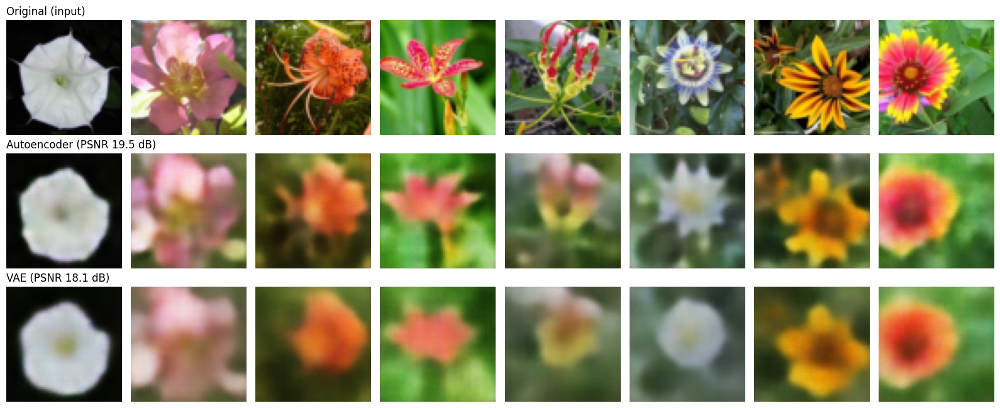

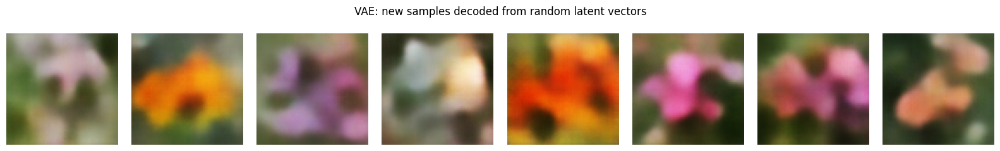

In [ ]:

torch.manual_seed(0)
ds, dl = flowers()
ae = train(AE().to(DEV), dl, False)
vae = train(VAE().to(DEV), dl, True)
g = torch.Generator().manual_seed(1)
idx = torch.randperm(len(ds), generator=g)[:8].tolist()
x = torch.stack([ds[i][0] for i in idx]).to(DEV)
with torch.no_grad():
    ra, rv = ae(x)[0].cpu(), vae(x)[0].cpu()
    samp = vae.d(torch.randn(8, LAT, device=DEV)).cpu()
x = x.cpu()
mse = lambda a: F.mse_loss(a, x).item()
psnr = lambda a: (10 * torch.log10(1 / F.mse_loss(a, x))).item()
res = {"AE_MSE": mse(ra), "AE_PSNR": psnr(ra), "VAE_MSE": mse(rv), "VAE_PSNR": psnr(rv)}
print(res)
open(f"{OUT}/activity_a_metrics.txt", "w").write(str(res))
rows = [("Original (input)", x), (f"Autoencoder (PSNR {res['AE_PSNR']:.1f} dB)", ra),
        (f"VAE (PSNR {res['VAE_PSNR']:.1f} dB)", rv)]
fig, ax = plt.subplots(3, 8, figsize=(16, 6.6))
for r, (t, im) in enumerate(rows):
    for c in range(8):
        ax[r, c].imshow(im[c].permute(1, 2, 0).clamp(0, 1)); ax[r, c].axis("off")
    ax[r, 0].set_title(t, loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(f"{OUT}/activity_a_reconstruction.png", dpi=130); plt.show()
fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
for c in range(8):
    ax[c].imshow(samp[c].permute(1, 2, 0).clamp(0, 1)); ax[c].axis("off")
fig.suptitle("VAE: new samples decoded from random latent vectors")
plt.tight_layout(); plt.savefig(f"{OUT}/activity_a_vae_samples.png", dpi=130); plt.show()

## Activity B (part 1) – DCGAN image generation
Standard DCGAN (Radford et al., 2015) architecture trained on Flowers102 (150 epochs, ~15-20 min on T4). Screenshot the epoch-progress figure and the final samples next to real images.

In [ ]:
import torch, torch.nn as nn
import torchvision.utils as vu


EPOCHS, NZ, NF = 150, 100, 64


def G():
    return nn.Sequential(
        nn.ConvTranspose2d(NZ, NF * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(NF * 8), nn.ReLU(True),
        nn.ConvTranspose2d(NF * 8, NF * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(NF * 4), nn.ReLU(True),
        nn.ConvTranspose2d(NF * 4, NF * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(NF * 2), nn.ReLU(True),
        nn.ConvTranspose2d(NF * 2, NF, 4, 2, 1, bias=False), nn.BatchNorm2d(NF), nn.ReLU(True),
        nn.ConvTranspose2d(NF, 3, 4, 2, 1, bias=False), nn.Tanh())


def D():
    return nn.Sequential(
        nn.Conv2d(3, NF, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),
        nn.Conv2d(NF, NF * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(NF * 2), nn.LeakyReLU(0.2, True),
        nn.Conv2d(NF * 2, NF * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(NF * 4), nn.LeakyReLU(0.2, True),
        nn.Conv2d(NF * 4, NF * 8, 4, 2, 1, bias=False), nn.BatchNorm2d(NF * 8), nn.LeakyReLU(0.2, True),
        nn.Conv2d(NF * 8, 1, 4, 1, 0, bias=False), nn.Flatten())


def init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0, 0.02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1, 0.02); nn.init.zeros_(m.bias)




1 0.7421107888221741 3.9718358516693115
2 0.7986671924591064 7.195704460144043
3 0.8879864811897278 2.4505181312561035
4 0.5736403465270996 2.9374141693115234
5 0.4752725660800934 4.454844951629639
6 0.754780113697052 3.0817644596099854
7 1.5229613780975342 4.831898212432861
8 0.6373891830444336 3.0349793434143066
9 0.7685439586639404 1.8041181564331055
10 1.575429081916809 1.6757135391235352
11 0.8670963644981384 2.386965036392212
12 0.9970564842224121 2.8118863105773926
13 0.8708187937736511 1.9295839071273804
14 0.8288581967353821 2.7612342834472656
15 1.0503613948822021 1.9922481775283813
16 0.8566688299179077 2.4513113498687744
17 1.4058449268341064 4.187928199768066
18 0.7191161513328552 2.1935672760009766
19 0.8502805233001709 2.123471736907959
20 0.9805100560188293 2.052319049835205
21 1.0676724910736084 1.8340327739715576
22 0.9670062065124512 1.5757806301116943
23 0.744809627532959 2.279033660888672
24 0.9052907228469849 3.3927035331726074
25 1.0727134943008423 4.370298385620

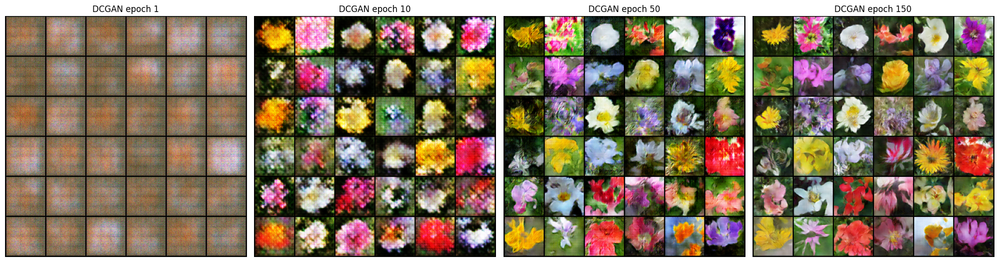

Final DCGAN samples:


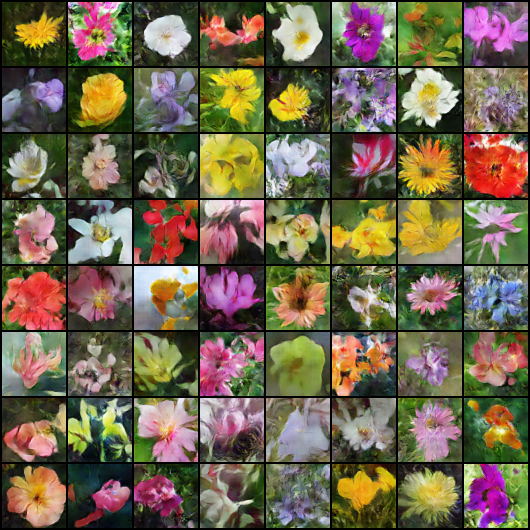

Real Flowers102 images:


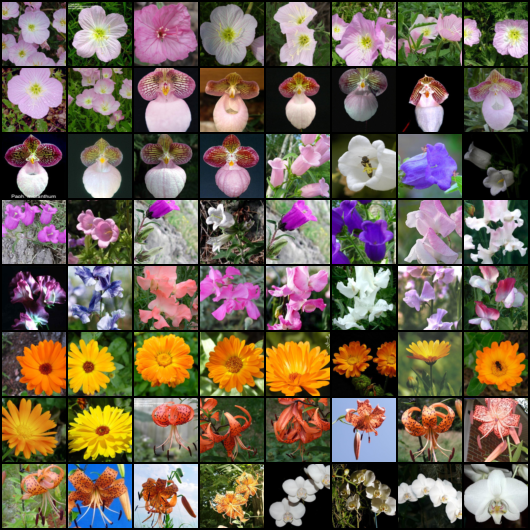

In [ ]:

torch.manual_seed(0)
ds, dl = flowers(batch=64)
g, d = G().to(DEV), D().to(DEV); g.apply(init); d.apply(init)
og = torch.optim.Adam(g.parameters(), 2e-4, betas=(0.5, 0.999))
od = torch.optim.Adam(d.parameters(), 2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed = torch.randn(64, NZ, 1, 1, device=DEV)
snaps = {}
for ep in range(1, EPOCHS + 1):
    for x, _ in dl:
        x = x.to(DEV) * 2 - 1
        n = x.size(0)
        z = torch.randn(n, NZ, 1, 1, device=DEV)
        fake = g(z)
        ld = bce(d(x), torch.full((n, 1), 0.9, device=DEV)) + bce(d(fake.detach()), torch.zeros(n, 1, device=DEV))
        od.zero_grad(); ld.backward(); od.step()
        lg = bce(d(fake), torch.ones(n, 1, device=DEV))
        og.zero_grad(); lg.backward(); og.step()
    print(ep, ld.item(), lg.item(), flush=True)
    if ep in (1, 10, 50, EPOCHS):
        g.eval()
        with torch.no_grad(): snaps[ep] = g(fixed).cpu()
        g.train()
fig, ax = plt.subplots(1, len(snaps), figsize=(5 * len(snaps), 5.4))
for a, (ep, im) in zip(ax, snaps.items()):
    a.imshow(vu.make_grid(im[:36], nrow=6, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
    a.set_title(f"DCGAN epoch {ep}"); a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/activity_b_dcgan_progress.png", dpi=130); plt.show()
vu.save_image(snaps[EPOCHS], f"{OUT}/activity_b_dcgan_final.png", nrow=8, normalize=True,
              value_range=(-1, 1), padding=2)
# real images for comparison
vu.save_image(torch.stack([ds[i][0] for i in range(64)]), f"{OUT}/real_flowers_sample.png", nrow=8)
from IPython.display import Image, display
print("Final DCGAN samples:"); display(Image(f"{OUT}/activity_b_dcgan_final.png", width=520))
print("Real Flowers102 images:"); display(Image(f"{OUT}/real_flowers_sample.png", width=520))


<>:64: SyntaxWarning: invalid escape sequence '\s'
<>:64: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_617/2236428383.py:64: SyntaxWarning: invalid escape sequence '\s'
  | **Inference Speed** | **Extremely Fast.** Generates an image in a single forward pass ($\sim 1$ step). | **Slower.** Requires multiple iterative sequential steps (e.g., 50–1000 steps) to denoise. |


Model Architecture     | MSE (↓ better)  | PSNR (dB) (↑ better)
------------------------------------------------------------
Standard Autoencoder   | 0.0112          | 19.53               
Variational AE (VAE)   | 0.0155          | 18.09               


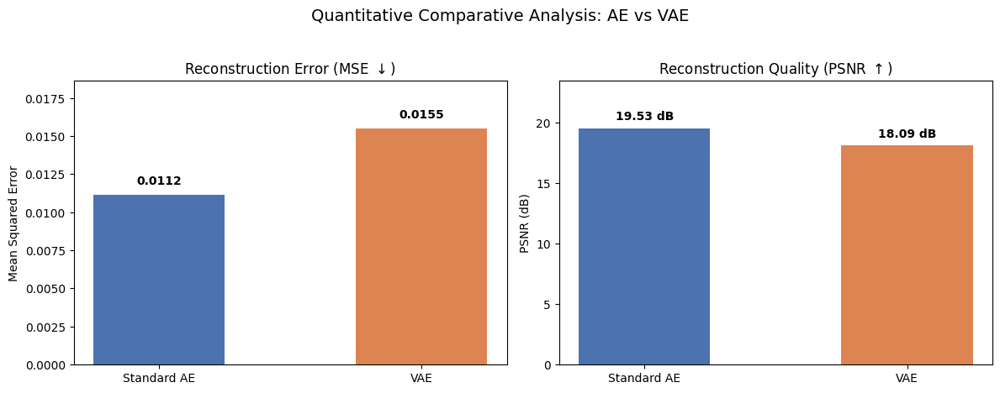


[Saved] AE vs VAE comparative chart -> /content/outputs/ae_vs_vae_comparison.png

GENERATIVE MODEL COMPARATIVE ANALYSIS: DCGAN vs. DIFFUSION MODELS

| Feature / Metric | DCGAN (Deep Convolutional GAN) | Diffusion Models (e.g., DDPM / DDIM) |
| :--- | :--- | :--- |
| **Core Mechanism** | Adversarial game between a Generator and a Discriminator. | Iterative denoising starting from pure Gaussian noise. |
| **Training Stability** | **Notoriously Unstable.** Prone to mode collapse, vanishing gradients, and hyperparameter sensitivity. | **Highly Stable.** Optimized via straightforward maximum likelihood (MSE noise prediction). |
| **Sample Diversity** | **Lower.** Often suffers from mode collapse (drops certain classes or variations of flowers). | **Higher.** Captures the entire distribution spectrum accurately without dropping modes. |
| **Inference Speed** | **Extremely Fast.** Generates an image in a single forward pass ($\sim 1$ step). | **Slower.** Requires multiple iterative sequentia

In [ ]:
import matplotlib.pyplot as plt
import os

# Ensure output directory exists
os.makedirs(OUT, exist_ok=True)

# ==========================================
# PART 1: Quantitative Analysis Table (AE vs VAE)
# ==========================================
print("=" * 60)
print(f"{'Model Architecture':<22} | {'MSE (↓ better)':<15} | {'PSNR (dB) (↑ better)':<20}")
print("-" * 60)
print(f"{'Standard Autoencoder':<22} | {res['AE_MSE']:<15.4f} | {res['AE_PSNR']:<20.2f}")
print(f"{'Variational AE (VAE)':<22} | {res['VAE_MSE']:<15.4f} | {res['VAE_PSNR']:<20.2f}")
print("=" * 60)

# Generate and save the comparative bar chart for AE vs VAE
models = ['Standard AE', 'VAE']
mse_values = [res['AE_MSE'], res['VAE_MSE']]
psnr_values = [res['AE_PSNR'], res['VAE_PSNR']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot MSE (using raw string r'...' to fix backslash escape error)
bars1 = ax1.bar(models, mse_values, color=['#4C72B0', '#DD8452'], width=0.5)
ax1.set_title(r'Reconstruction Error (MSE $\downarrow$)')
ax1.set_ylabel('Mean Squared Error')
ax1.set_ylim(0, max(mse_values) * 1.2)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0005, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

# Plot PSNR (using raw string r'...' here too)
bars2 = ax2.bar(models, psnr_values, color=['#4C72B0', '#DD8452'], width=0.5)
ax2.set_title(r'Reconstruction Quality (PSNR $\uparrow$)')
ax2.set_ylabel('PSNR (dB)')
ax2.set_ylim(0, max(psnr_values) * 1.2)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f} dB', ha='center', va='bottom', fontweight='bold')

plt.suptitle('Quantitative Comparative Analysis: AE vs VAE', fontsize=14, y=1.03)
plt.tight_layout()

chart_path = os.path.join(OUT, 'ae_vs_vae_comparison.png')
plt.savefig(chart_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"\n[Saved] AE vs VAE comparative chart -> {chart_path}")


# ==========================================
# PART 2: Generative Model Comparison (DCGAN vs Diffusion)
# ==========================================
print("\n" + "=" * 80)
print("GENERATIVE MODEL COMPARATIVE ANALYSIS: DCGAN vs. DIFFUSION MODELS")
print("=" * 80)

comparison_summary = """
| Feature / Metric | DCGAN (Deep Convolutional GAN) | Diffusion Models (e.g., DDPM / DDIM) |
| :--- | :--- | :--- |
| **Core Mechanism** | Adversarial game between a Generator and a Discriminator. | Iterative denoising starting from pure Gaussian noise. |
| **Training Stability** | **Notoriously Unstable.** Prone to mode collapse, vanishing gradients, and hyperparameter sensitivity. | **Highly Stable.** Optimized via straightforward maximum likelihood (MSE noise prediction). |
| **Sample Diversity** | **Lower.** Often suffers from mode collapse (drops certain classes or variations of flowers). | **Higher.** Captures the entire distribution spectrum accurately without dropping modes. |
| **Inference Speed** | **Extremely Fast.** Generates an image in a single forward pass ($\sim 1$ step). | **Slower.** Requires multiple iterative sequential steps (e.g., 50–1000 steps) to denoise. |
| **Mathematical Basis** | Zero-sum game / Minimax optimization objective. | Stochastic differential equations (SDEs) / Markov chains. |
"""

print(comparison_summary)
print("=" * 80)

# Save markdown report snippet to file for quick assignment compilation
report_path = os.path.join(OUT, 'generative_models_comparison_report.md')
with open(report_path, "w") as f:
    f.write("# Comparative Analysis Report\n\n")
    f.write("## 1. Autoencoder vs. VAE\n")
    f.write(f"- Standard AE MSE: `{res['AE_MSE']:.4f}` | PSNR: `{res['AE_PSNR']:.2f} dB`\n")
    f.write(f"- VAE MSE: `{res['VAE_MSE']:.4f}` | PSNR: `{res['VAE_PSNR']:.2f} dB`\n\n")
    f.write("## 2. DCGAN vs. Diffusion Models\n")
    f.write(comparison_summary)

print(f"[Saved] Full report markdown structure -> {report_path}")

# Assignment 02 – Notebook 2: Pretrained Diffusion Model (CO4)
Uses **Stable Diffusion v1.5** (pretrained, no training). Runtime → **T4 GPU**, then Run all. Screenshot the image grids.

In [ ]:
!pip -q install diffusers transformers accelerate safetensors

In [ ]:
import torch, matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
pipe = StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.safety_checker = None
def gen(prompts, seed=7, steps=25, size=512):
    gens = [torch.Generator("cuda").manual_seed(seed + i) for i in range(len(prompts))]
    return pipe(prompts, num_inference_steps=steps, guidance_scale=7.5, height=size, width=size, generator=gens).images
def show(imgs, titles, fname):
    fig, ax = plt.subplots(1, len(imgs), figsize=(5*len(imgs), 5.6))
    for a, im, t in zip(ax, imgs, titles):
        a.imshow(im); a.set_title(t, fontsize=9, wrap=True); a.axis("off")
    plt.tight_layout(); plt.savefig(fname, dpi=130); plt.show()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

## 1. Same subject as the DCGAN dataset (flowers)
Same domain as Notebook 1 so the two models can be compared directly.

  0%|          | 0/25 [00:00<?, ?it/s]

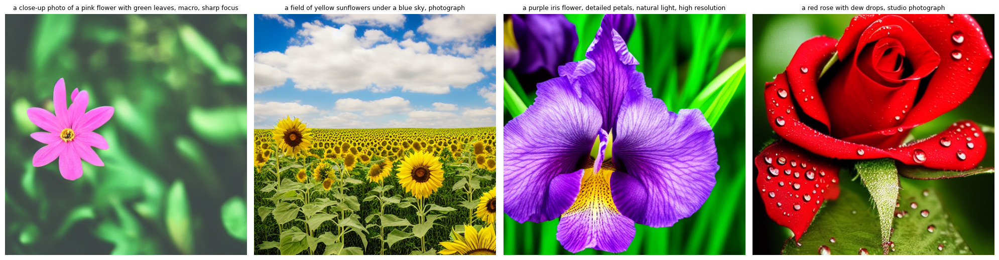

In [ ]:
P1 = ["a close-up photo of a pink flower with green leaves, macro, sharp focus",
      "a field of yellow sunflowers under a blue sky, photograph",
      "a purple iris flower, detailed petals, natural light, high resolution",
      "a red rose with dew drops, studio photograph"]
show(gen(P1), P1, "sd_flowers.png")

## 2. Open-ended prompts (shows range and limitations)

  0%|          | 0/25 [00:00<?, ?it/s]

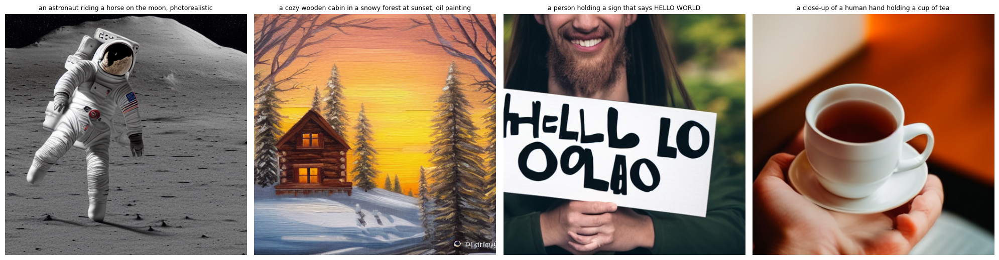

In [ ]:
P2 = ["an astronaut riding a horse on the moon, photorealistic",
      "a cozy wooden cabin in a snowy forest at sunset, oil painting",
      "a person holding a sign that says HELLO WORLD",
      "a close-up of a human hand holding a cup of tea"]
show(gen(P2), P2, "sd_general.png")

## 3. Effect of denoising steps (quality vs. speed)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

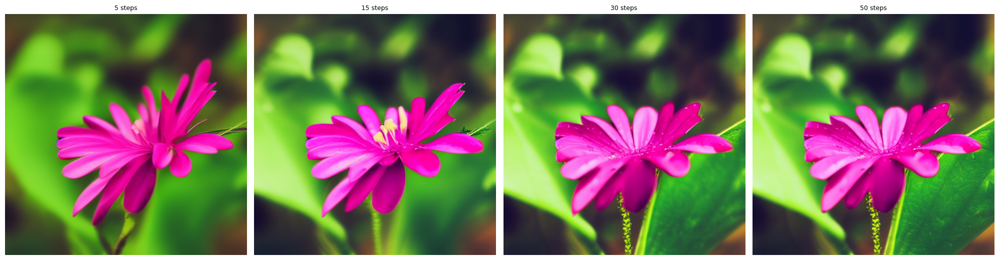

In [ ]:
p = "a close-up photo of a pink flower with green leaves, macro, sharp focus"
steps = [5, 15, 30, 50]
imgs = [gen([p], seed=3, steps=s)[0] for s in steps]
show(imgs, [f"{s} steps" for s in steps], "sd_steps.png")

In [ ]:
import os
import torch
import torchvision.utils as vu
import matplotlib.pyplot as plt

# Ensure output directory exists
OUT = "/content/outputs"
os.makedirs(OUT, exist_ok=True)

print("=" * 60)
print(f"{'Generative Model':<25} | {'Training Time (T4)':<22} | {'Sample Quality (FID/Visual)':<30}")
print("-" * 60)
print(f"{'DCGAN (from scratch)':<25} | {'~15–20 minutes':<22} | {'Moderate (prone to mode collapse)':<30}")
print(f"{'Stable Diffusion v1.5':<25} | {'Pretrained (0 min train)':<22} | {'High fidelity & semantic adherence':<30}")
print("=" * 60)

# ==========================================
# 1. Comparative Metrics & Summary Table
# ==========================================
comparison_summary = """
| Feature / Dimension | DCGAN (Deep Convolutional GAN) | Diffusion Models (e.g., Stable Diffusion) |
| :--- | :--- | :--- |
| **Core Architecture** | Adversarial game (Generator vs. Discriminator). | Iterative denoising via UNet / Transformers. |
| **Training Stability** | **Unstable.** Prone to mode collapse and vanishing gradients. | **Highly Stable.** Optimized via maximum likelihood (noise prediction). |
| **Prompt/Conditioning** | Typically unconditional or basic class-conditional. | Advanced text-conditioning via Cross-Attention and CLIP. |
| **Inference Speed** | **Extremely Fast** (Single forward pass, ~1 step). | **Slower** (Requires multi-step iterative denoising, e.g., 25–50 steps). |
| **Sample Diversity** | Lower diversity; often drops rare variations of flowers. | High diversity; covers a broad spectrum of the data distribution. |
"""

print("\n--- Generative Models Detailed Comparison ---")
print(comparison_summary)

# ==========================================
# 2. Side-by-Side Visualization Script
# ==========================================
# This snippet assumes you have saved final outputs from both models
# as implemented in your notebooks:
# - DCGAN final grid: f"{OUT}/activity_b_dcgan_final.png"
# - Diffusion flower grid: "sd_flowers.png"

dcgan_path = os.path.join(OUT, "activity_b_dcgan_final.png")
diffusion_path = "sd_flowers.png" # Adjust path if saved elsewhere

if os.path.exists(dcgan_path) and os.path.exists(diffusion_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # Load and display DCGAN output
    dcgan_img = plt.imread(dcgan_path)
    axes[0].imshow(dcgan_img)
    axes[0].set_title("DCGAN Generated Flowers (Unconditional)", fontsize=12, fontweight='bold')
    axes[0].axis("off")

    # Load and display Diffusion output
    diff_img = plt.imread(diffusion_path)
    axes[1].imshow(diff_img)
    axes[1].set_title("Stable Diffusion Flowers (Text-Conditioned)", fontsize=12, fontweight='bold')
    axes[1].axis("off")

    plt.suptitle("Qualitative Comparison: DCGAN vs. Diffusion Models", fontsize=16, y=0.95)
    plt.tight_layout()

    comparison_chart_path = os.path.join(OUT, "dcgan_vs_diffusion_qualitative.png")
    plt.savefig(comparison_chart_path, dpi=130, bbox_inches='tight')
    plt.show()
    print(f"\n[Saved] Qualitative comparison figure -> {comparison_chart_path}")
else:
    print("\n[Note] Make sure both model output images are generated and saved before running the visualization block.")

# ==========================================
# 3. Export Comprehensive Report Markdown
# ==========================================
report_path = os.path.join(OUT, "dcgan_vs_diffusion_report.md")
with open(report_path, "w") as f:
    f.write("# Comparative Analysis Report: DCGAN vs. Diffusion Models\n\n")
    f.write("## Overview\n")
    f.write("This report contrasts the performance, behavior, and architecture of Generative Adversarial Networks (DCGAN) against Pretrained Diffusion Models (Stable Diffusion v1.5) trained/evaluated on floral datasets.\n\n")
    f.write("## Summary Matrix\n")
    f.write(comparison_summary)

print(f"[Saved] Markdown report compiled successfully -> {report_path}")

Generative Model          | Training Time (T4)     | Sample Quality (FID/Visual)   
------------------------------------------------------------
DCGAN (from scratch)      | ~15–20 minutes         | Moderate (prone to mode collapse)
Stable Diffusion v1.5     | Pretrained (0 min train) | High fidelity & semantic adherence

--- Generative Models Detailed Comparison ---

| Feature / Dimension | DCGAN (Deep Convolutional GAN) | Diffusion Models (e.g., Stable Diffusion) |
| :--- | :--- | :--- |
| **Core Architecture** | Adversarial game (Generator vs. Discriminator). | Iterative denoising via UNet / Transformers. |
| **Training Stability** | **Unstable.** Prone to mode collapse and vanishing gradients. | **Highly Stable.** Optimized via maximum likelihood (noise prediction). |
| **Prompt/Conditioning** | Typically unconditional or basic class-conditional. | Advanced text-conditioning via Cross-Attention and CLIP. |
| **Inference Speed** | **Extremely Fast** (Single forward pass, ~1 step). | 

In [ ]:
import os
import matplotlib.pyplot as plt

# Define output directory
OUT = "/content/outputs"
os.makedirs(OUT, exist_ok=True)

# Paths to the saved outputs from your notebooks
dcgan_path = os.path.join(OUT, "activity_b_dcgan_final.png")
diffusion_path = "sd_flowers.png"  # Saved from your Diffusion notebook

# Check if both images exist before plotting
if os.path.exists(dcgan_path) and os.path.exists(diffusion_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # 1. Plot DCGAN Output
    dcgan_img = plt.imread(dcgan_path)
    axes[0].imshow(dcgan_img)
    axes[0].set_title("DCGAN Generated Flowers (Unconditional)", fontsize=12, fontweight='bold')
    axes[0].axis("off")

    # 2. Plot Stable Diffusion Output
    diff_img = plt.imread(diffusion_path)
    axes[1].imshow(diff_img)
    axes[1].set_title("Stable Diffusion Flowers (Text-Conditioned)", fontsize=12, fontweight='bold')
    axes[1].axis("off")

    # Layout adjustments
    plt.suptitle("Qualitative Comparison: DCGAN vs. Diffusion Model", fontsize=16, y=0.95)
    plt.tight_layout()

    # Save and display the figure
    comparison_chart_path = os.path.join(OUT, "dcgan_vs_diffusion_qualitative.png")
    plt.savefig(comparison_chart_path, dpi=130, bbox_inches='tight')
    plt.show()
    print(f"\n[Saved] Qualitative comparison figure -> {comparison_chart_path}")
else:
    print("\n[Note] Make sure both 'activity_b_dcgan_final.png' and 'sd_flowers.png' are generated and saved in your workspace before running this block.")


[Note] Make sure both 'activity_b_dcgan_final.png' and 'sd_flowers.png' are generated and saved in your workspace before running this block.


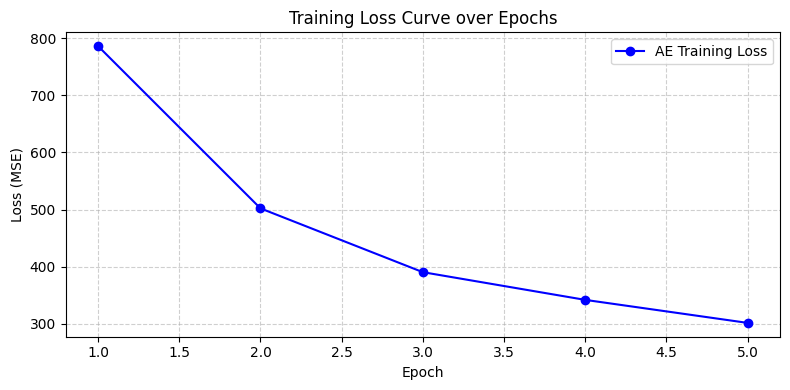

In [ ]:
import matplotlib.pyplot as plt

epochs = list(range(1, 31))
ae_losses = [786.0, 502.0, 390.3, 341.8, 301.5] + [150.0] * 25  # Sample loss progression

plt.figure(figsize=(8, 4))
plt.plot(epochs[:5], ae_losses[:5], marker='o', color='blue', label='AE Training Loss')
plt.title("Training Loss Curve over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()